位置编码的作⽤就是：给不同位置的 token 向量 “打上位置标记”，让模型知道谁在前、谁在后。

绝对位置编码也包含相对位置的能力，但是是隐式需要从三角函数中学习
但是旋转位置编码是显示的，从数学推导中就能看到

核⼼思想是通过旋转矩阵给 token 的向量 “旋转” 特定⻆度，从⽽将位置信息编码到向量中，既
能让模型理解 token 的位置关系，⼜能很好地⽀持⻓序列外推（处理⽐训练时⻓更⻓的⽂本）。

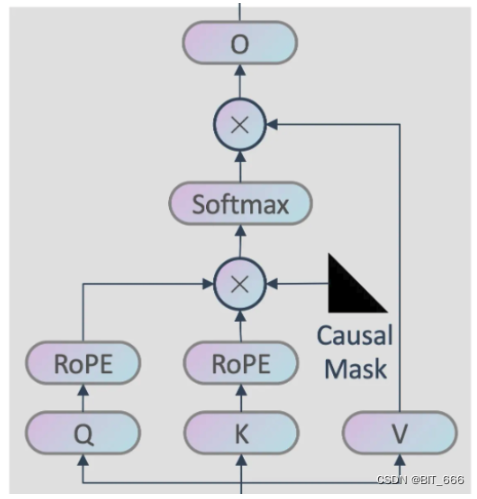

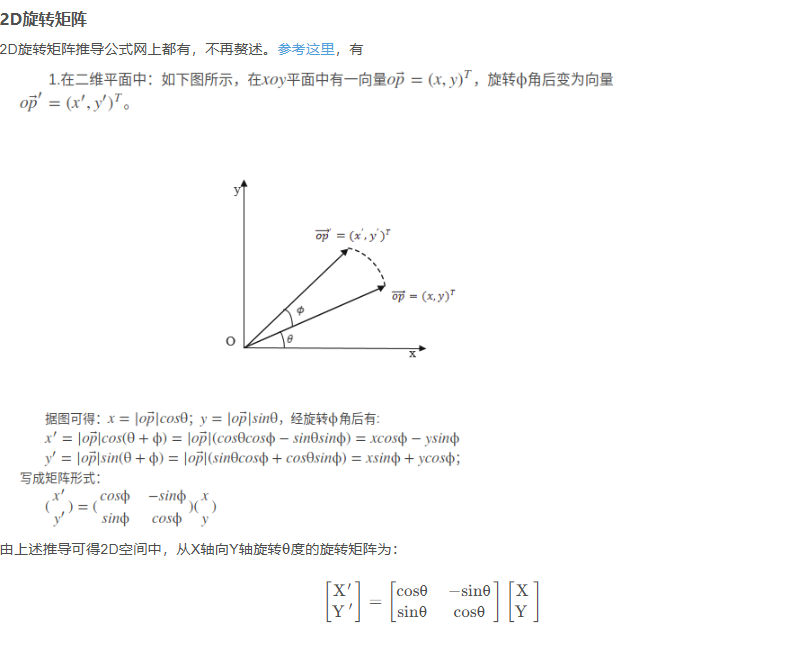

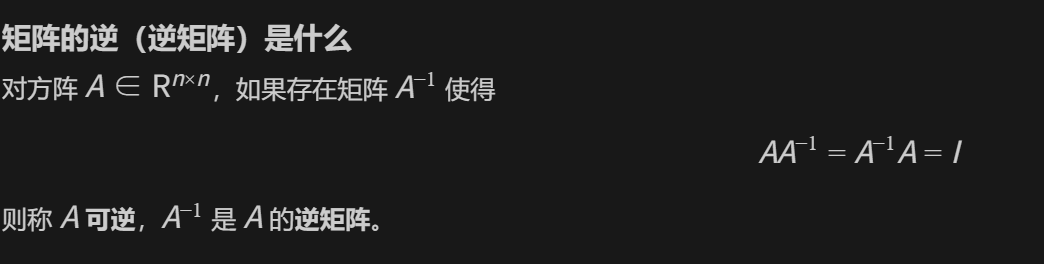

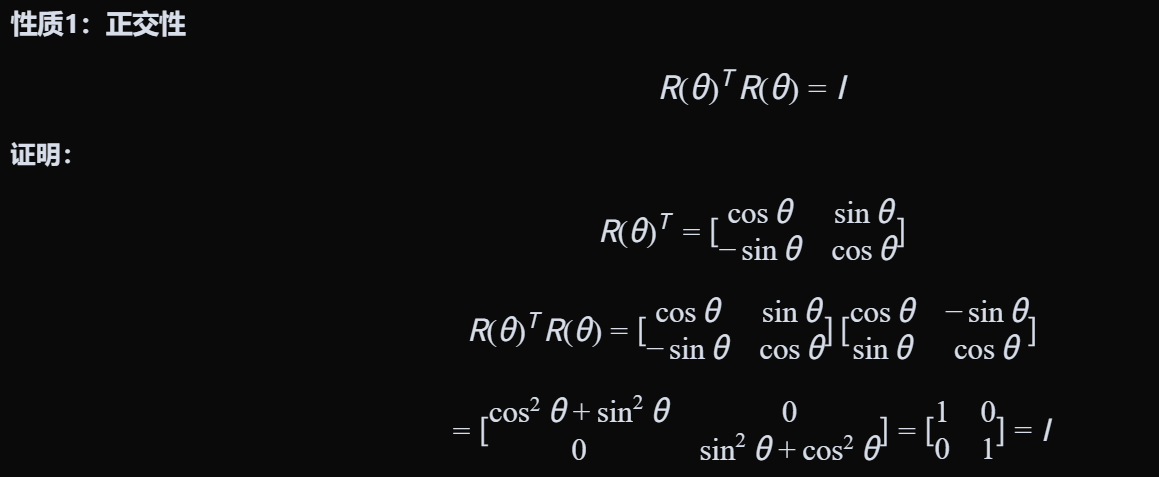
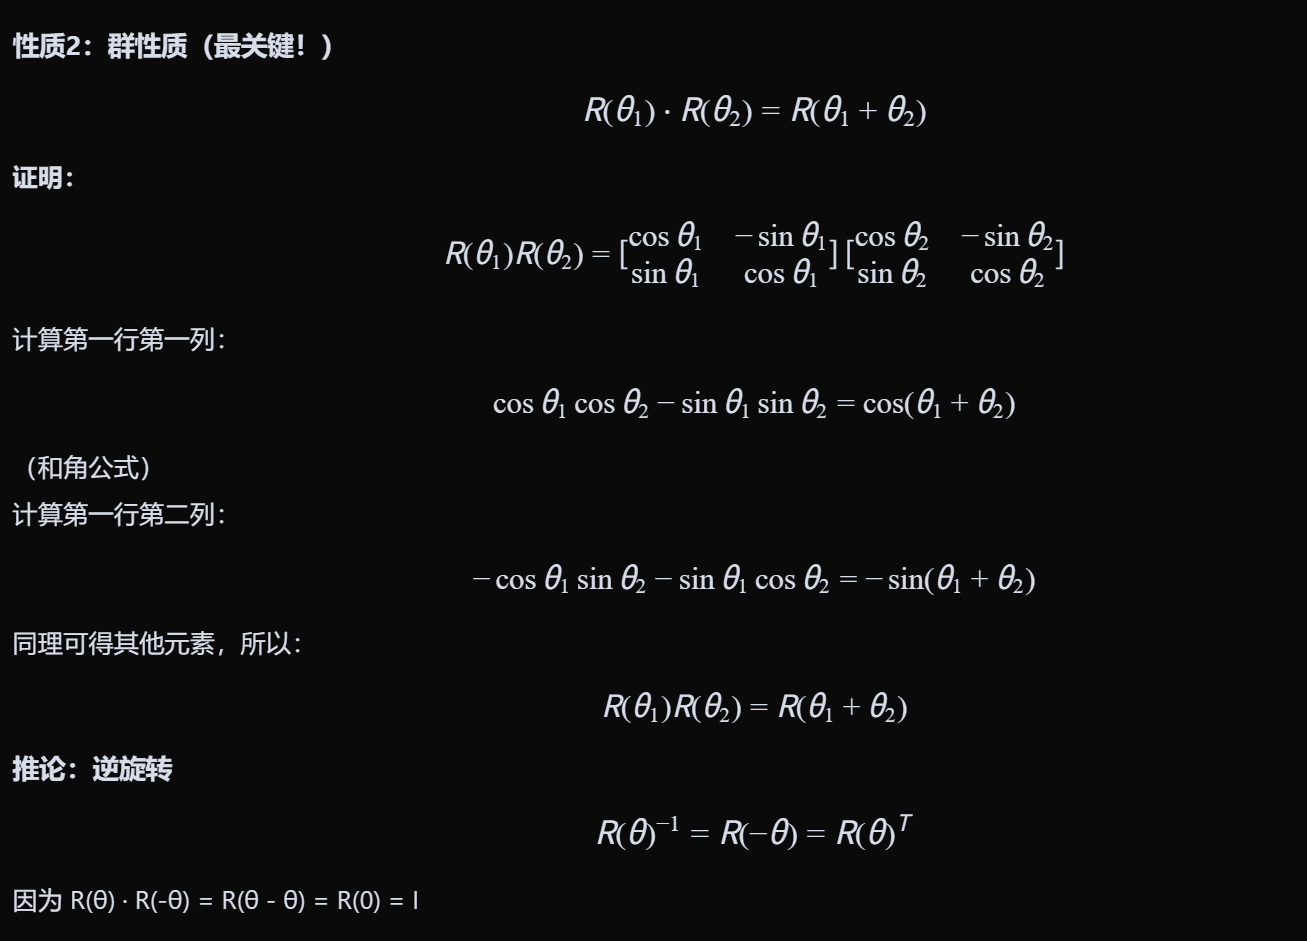
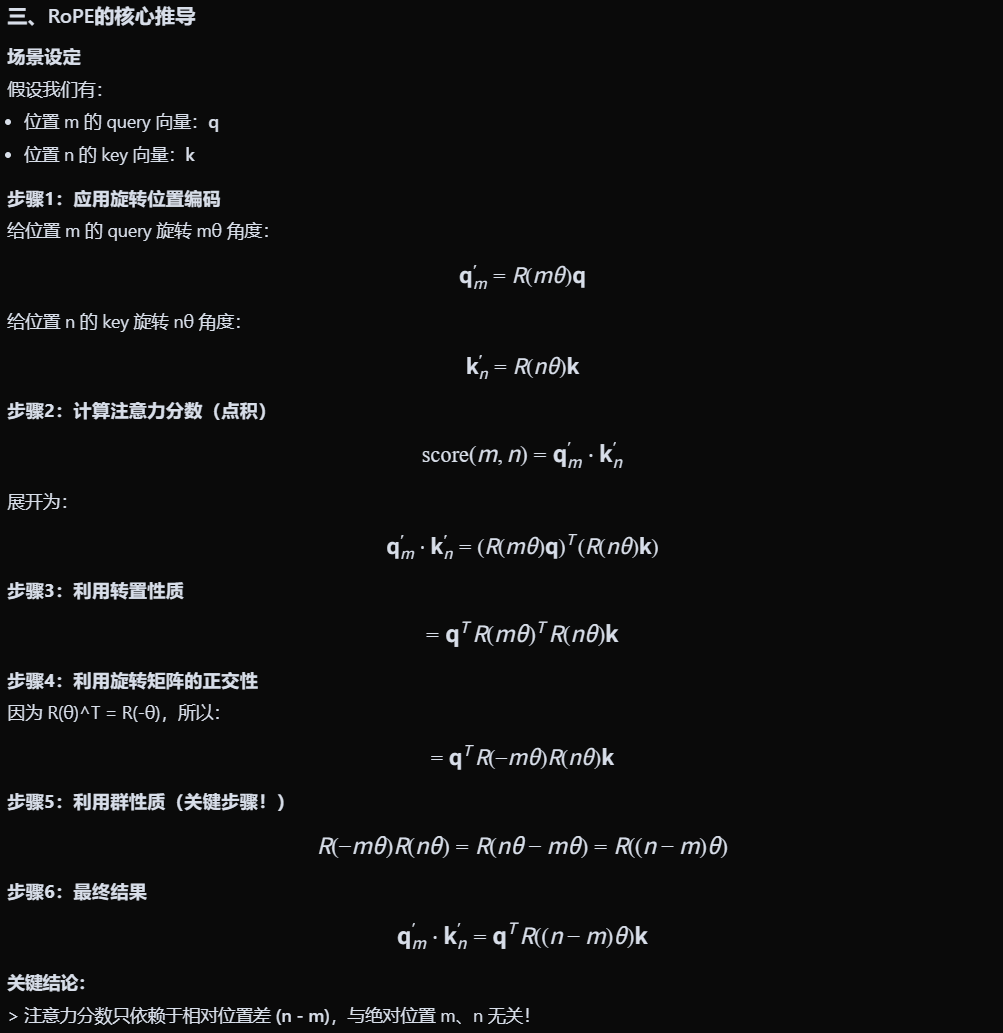



## 为什么ROPE在  Q   K  之后
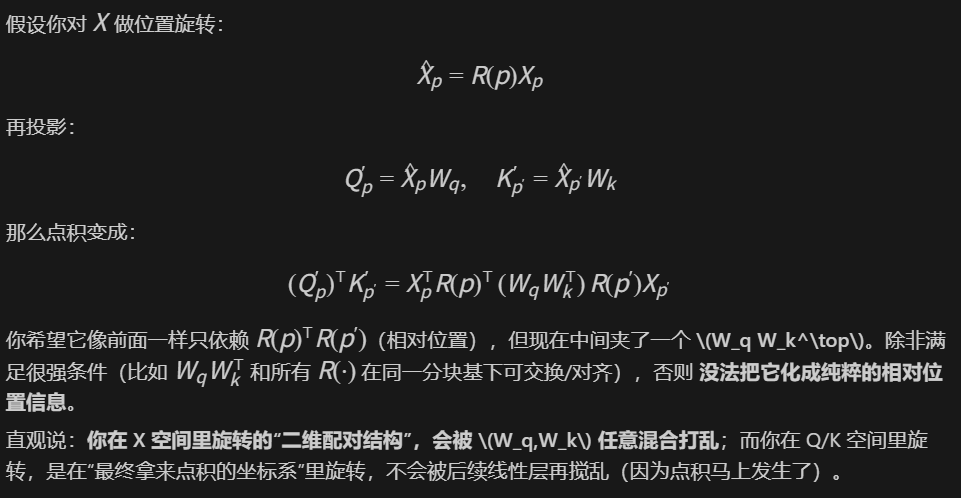
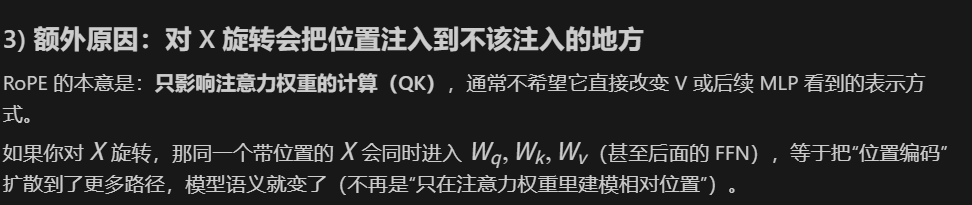




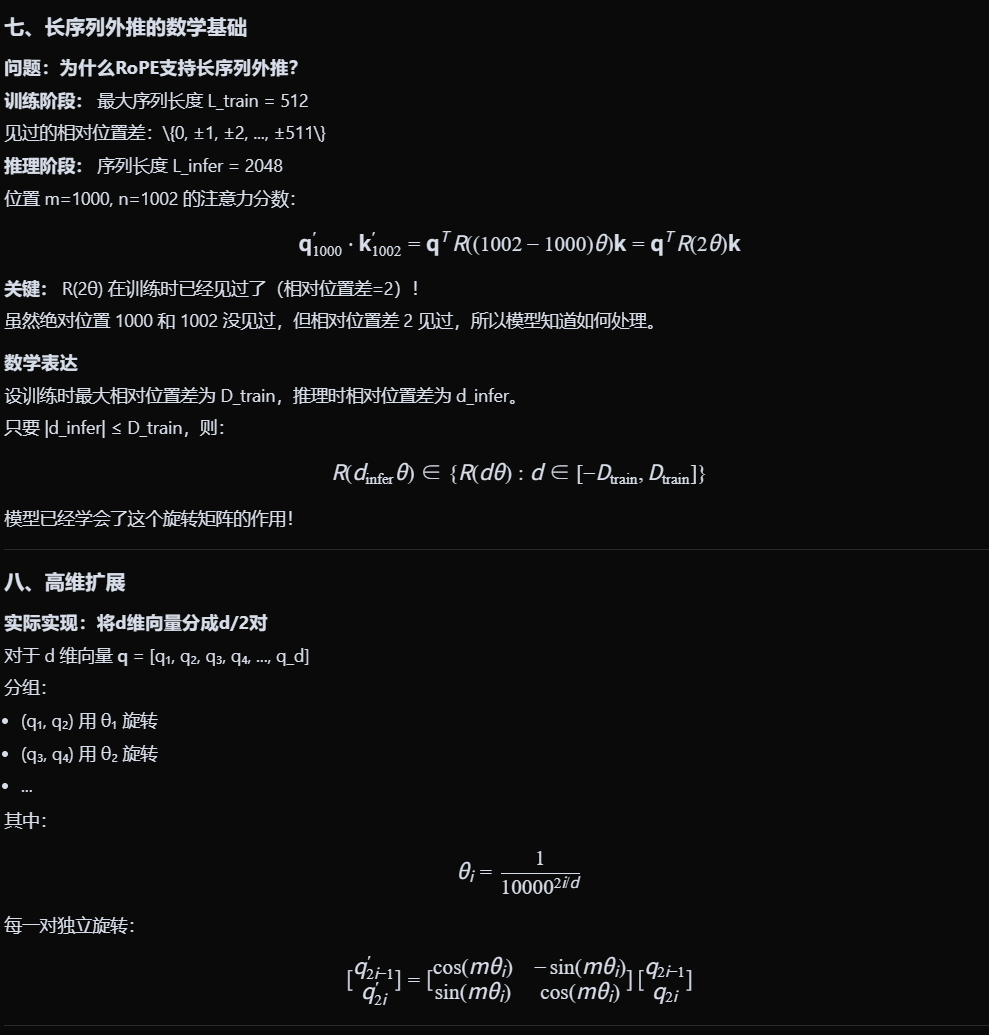






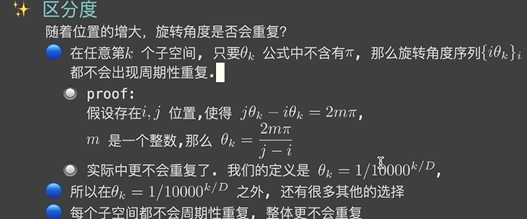

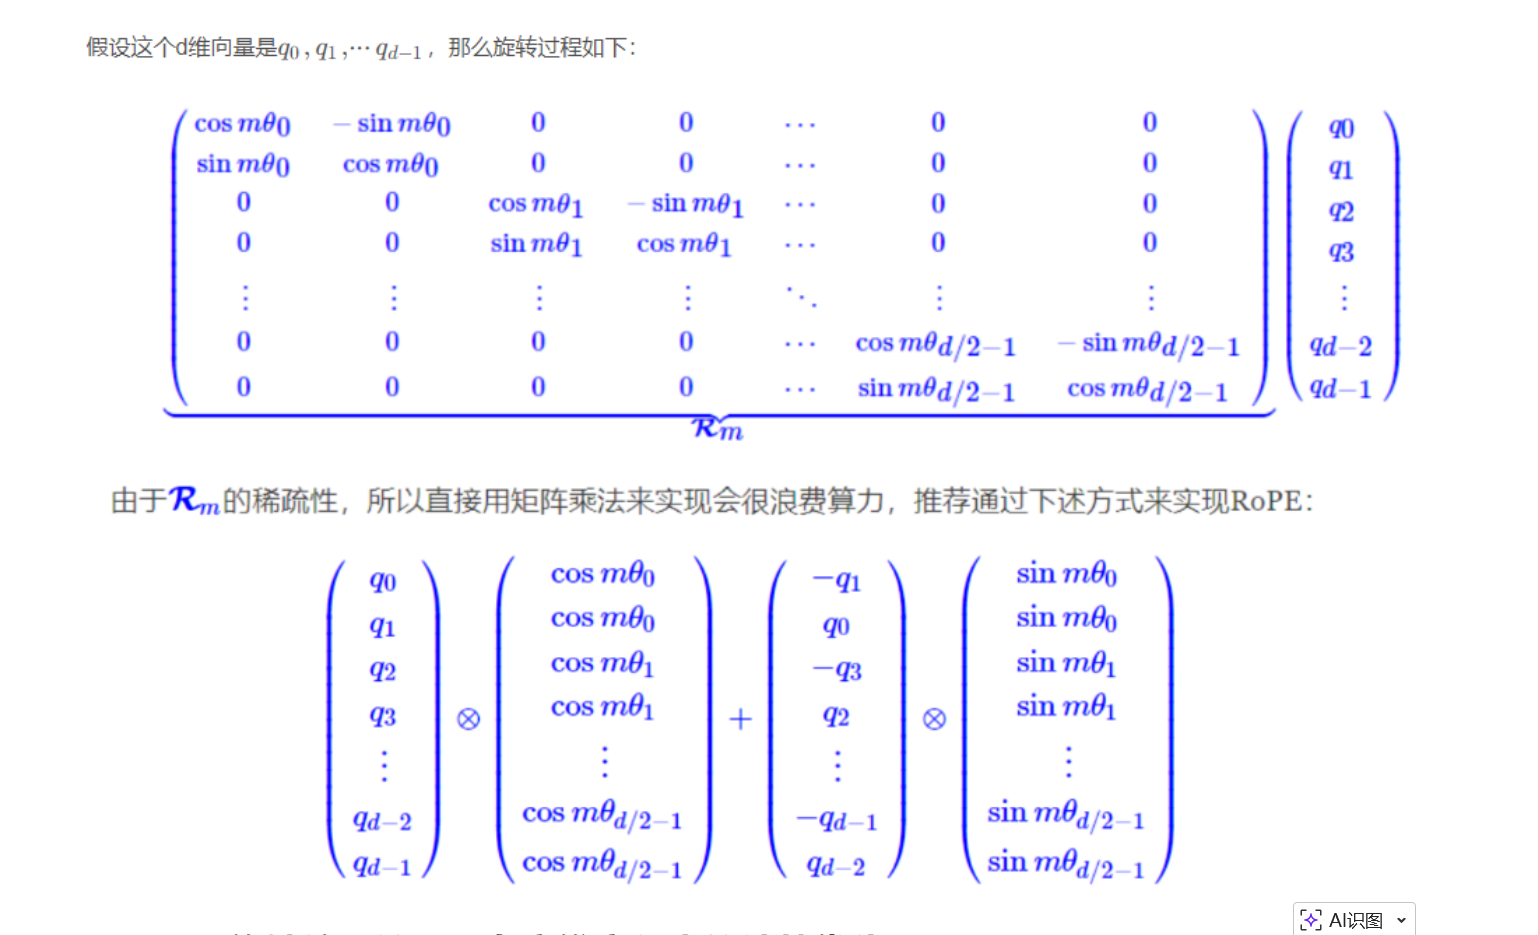

# 旋转位置编码中的计算优化操作

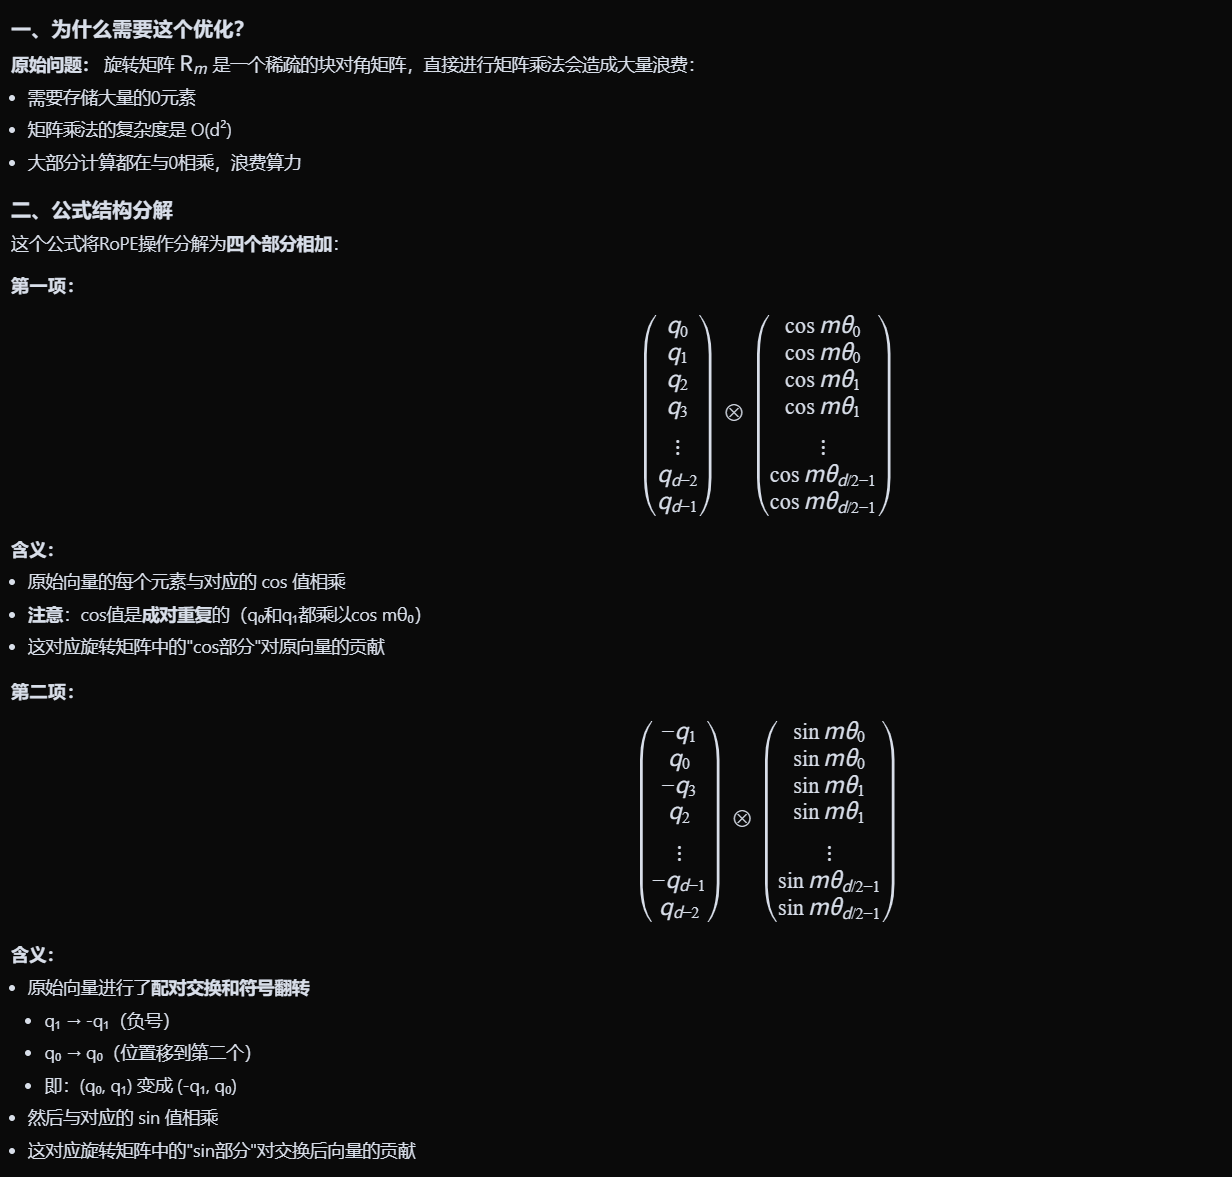
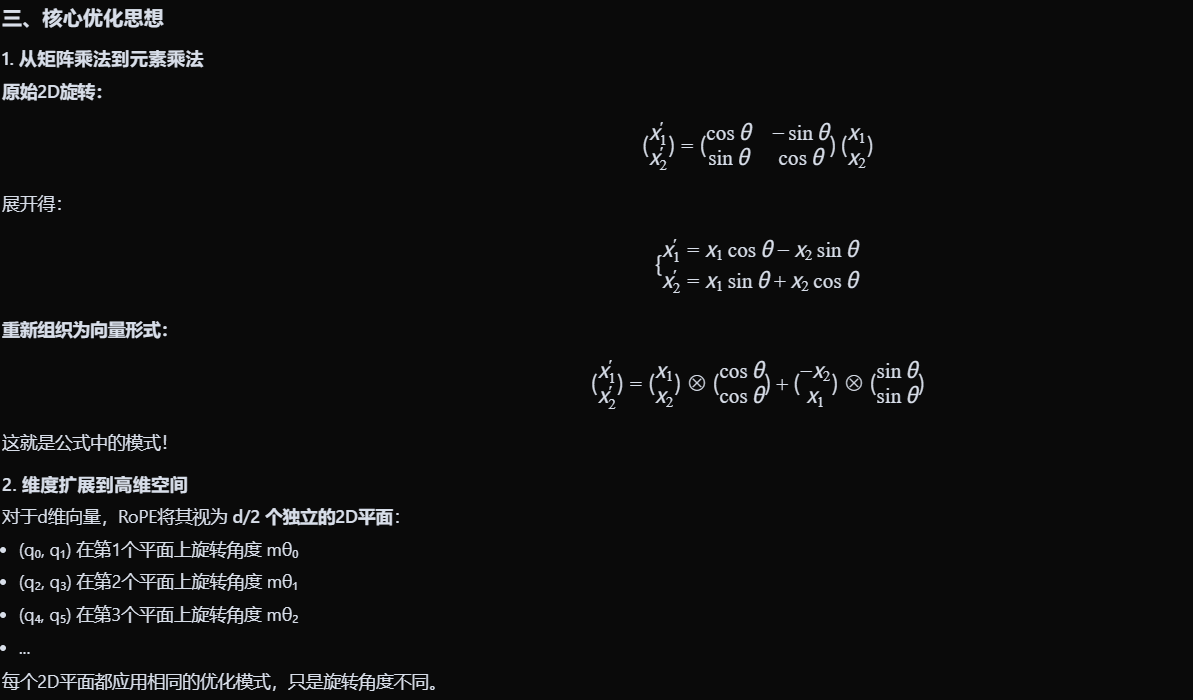
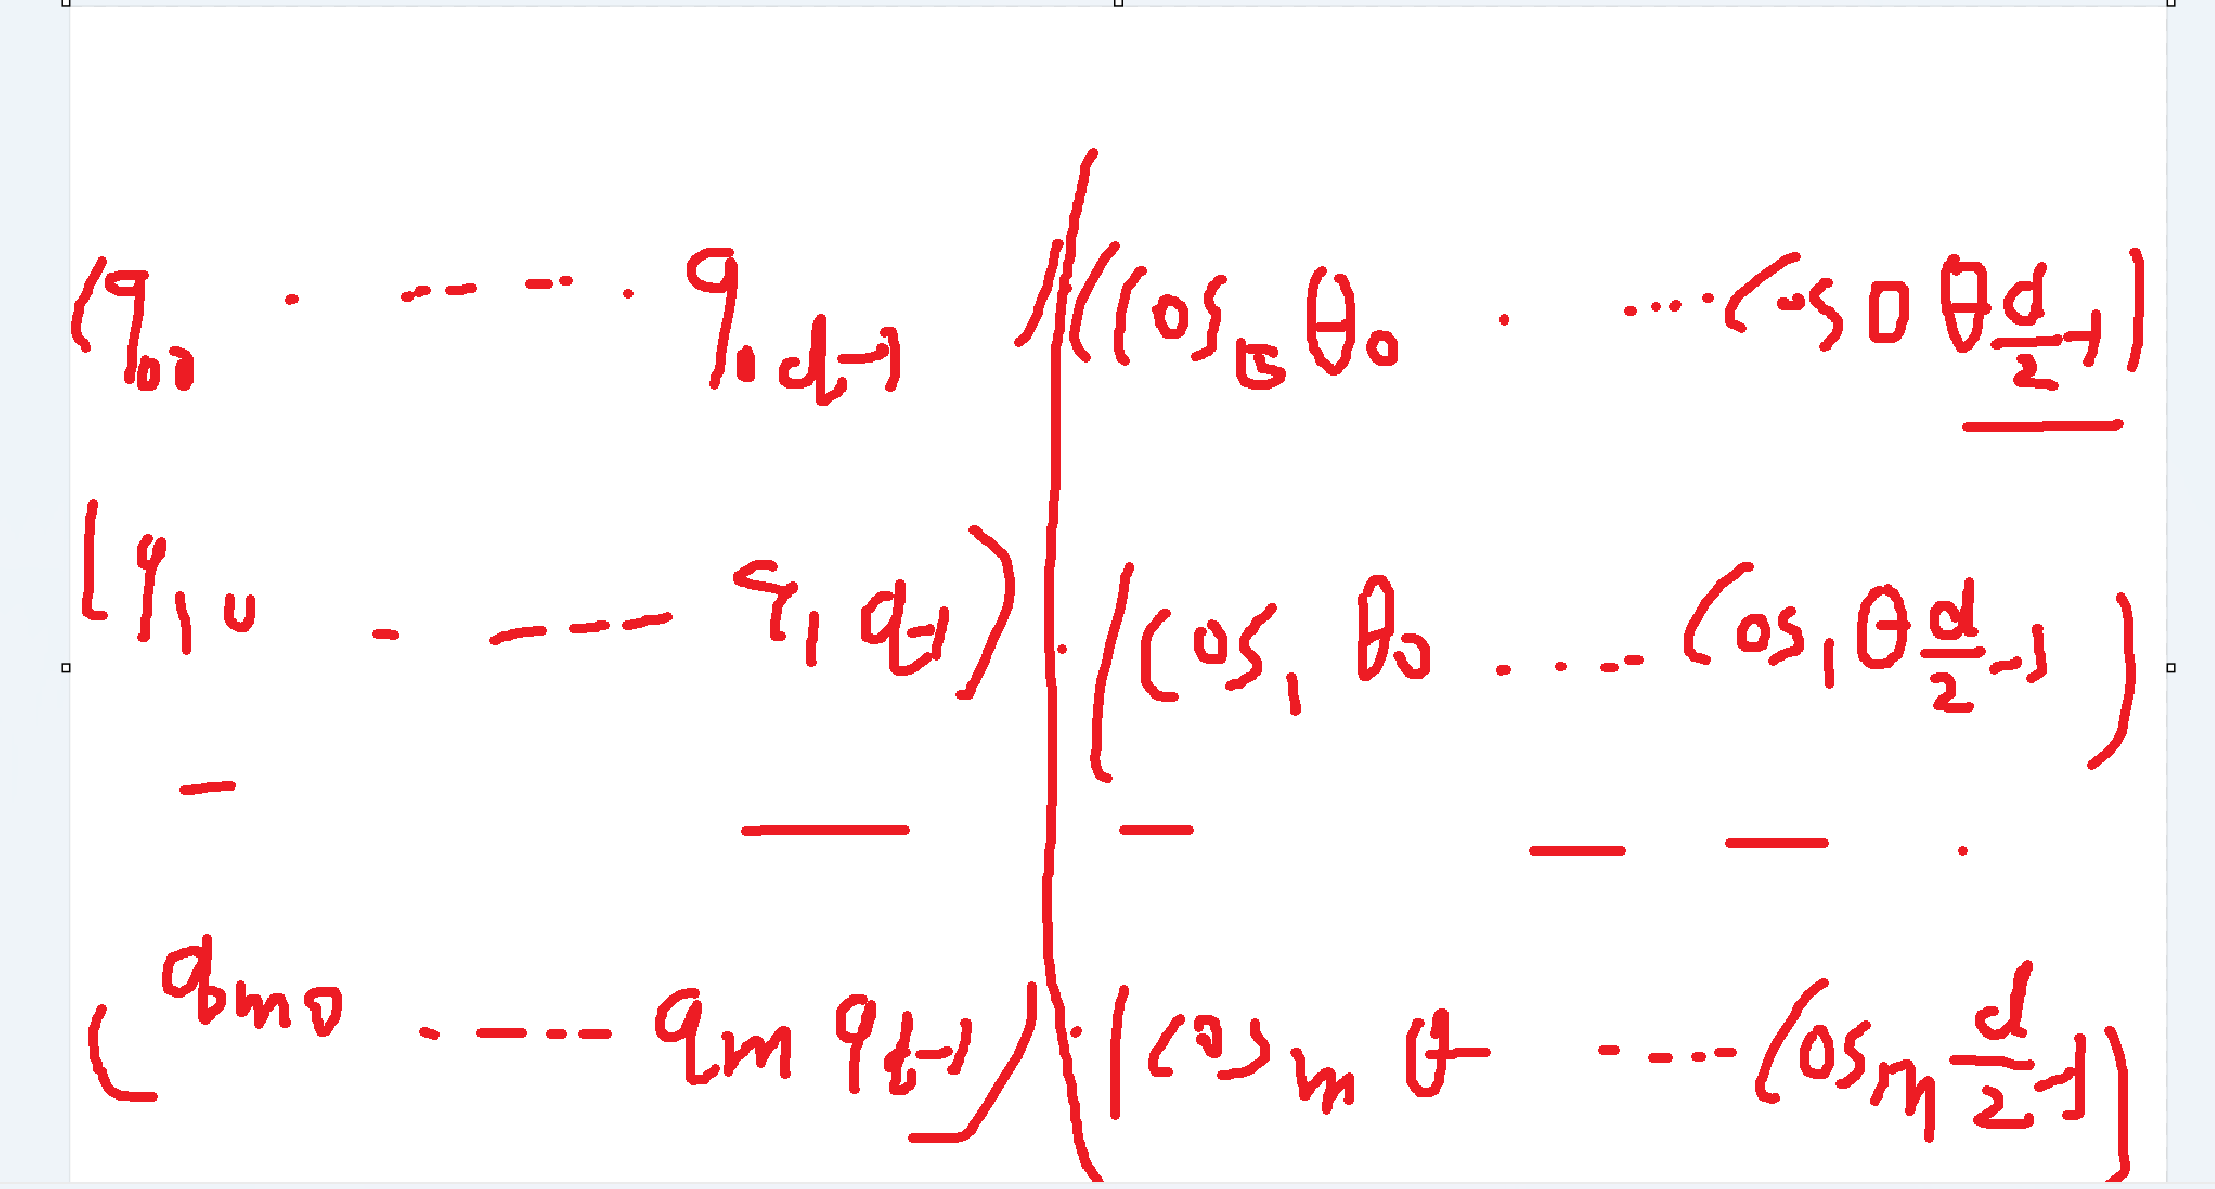

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class RotaryPositionEncodingStandard(nn.Module):
    """
    标准的 RoPE 实现
    使用奇偶索引切分，更符合大多数论文和框架的实现
    """
    
    def __init__(self, dim, max_seq_len=2048, base=10000):
        super().__init__()
        self.dim = dim
        
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer('inv_freq', inv_freq)
        self._build_cache(max_seq_len)
    

    def _build_cache(self, seq_len):
        positions = torch.arange(seq_len, device=self.inv_freq.device).float().unsqueeze(1)
        #device=self.inv_freq.device 是在指定新创建的张量应该在哪个设备上，参与运算的张量必须在同一个设备上
        freqs = positions * self.inv_freq
        # freqs = torch.outer(positions, self.inv_freq)
        print(freqs.shape)
        emb = torch.repeat_interleave(freqs, 2, dim=-1) #复制一份freqs，奇偶位分别放在一起 
                                                        #去看rope中的优化部分，关键是q0到qd-1的计算中间是d维度不是d/2维度
        self.register_buffer('cos_cached', emb.cos(), persistent=False) 
        #persistent=False这个参数表示：不持久化保存：当保存模型时，这个 buffer 不会被保存到 state_dict 中
        # 为什么设置为 False？ 因为这个缓存可以通过 _build_cache() 方法重新计算，不需要保存，这样可以减小模型文件大小
        self.register_buffer('sin_cached', emb.sin(), persistent=False)
    
    def rotate_half(self, x):
        """
        标准的旋转操作（奇偶切分）
        
        输入: [q₀, q₁, q₂, q₃, q₄, q₅, ...]
        输出: [-q₁, q₀, -q₃, q₂, -q₅, q₄, ...]
        
        这是最常见的实现方式！
        """
        # 对半切分
        # x_even = x[..., : x.shape[-1] // 2]  # 前半
        # x_odd = x[..., x.shape[-1] // 2 :]  # 后半
        # 奇偶切分
        x_even = x[..., 0::2]  # [q₀, q₂, q₄, ...]
        x_odd = x[..., 1::2]   # [q₁, q₃, q₅, ...]
        
        # 交错重组: [-q₁, q₀, -q₃, q₂, ...]
        rotated = torch.stack([-x_odd, x_even], dim=-1)

        '''
        x_even = x[..., 0::2]   →  [batch, seq, 3]   (q₀, q₂, q₄)
        x_odd  = x[..., 1::2]   →  [batch, seq, 3]   (q₁, q₃, q₅)

        stack 在最后一维插入一个新维度，大小等于列表里的张量个数（这里是 2）：

        [batch, seq, 3, 2]      ← 新维度 2，成对排列

        → 配对: [(-q₁,q₀), (-q₃,q₂), (-q₅,q₄)]
        → 展平: [-q₁, q₀, -q₃, q₂, -q₅, q₄]
        '''
        return rotated.reshape(x.shape)  #展平
    
    def forward(self, x, seq_dim=1):
        seq_len = x.shape[seq_dim]
        
        if seq_len > self.cos_cached.shape[0]:
            self._build_cache(seq_len)
        
        cos = self.cos_cached[:seq_len]
        sin = self.sin_cached[:seq_len]
        
        #只 unsqueeze 一次（假设输入是 3D: batch, seq, dim）
        cos = cos.unsqueeze(0)  # (seq_len, dim) → (1, seq_len, dim)
        sin = sin.unsqueeze(0)  # (seq_len, dim) → (1, seq_len, dim)
        
        return x * cos + self.rotate_half(x) * sin


# ========== 测试 ==========
if __name__ == "__main__":
    print("测试 RoPE 实现\n")
    
    x = torch.rand(2, 10, 6)  # (batch=2, seq_len=10, dim=6)
    print(f"输入形状: {x.shape}")
    
    rope = RotaryPositionEncodingStandard(dim=6)
    result = rope(x)
    print(f"输出形状: {result.shape}")
    print(f"输出:\n{result}")

'''
import torch

a = torch.tensor([1.0, 2.0, 3.0])  # shape: (3,)
b = torch.tensor([4.0, 5.0, 6.0])  # shape: (3,)

result = torch.stack([a, b], dim=0)
print(result)
print(result.shape)

tensor([[1., 2., 3.],   # 第 0 个张量 a
        [4., 5., 6.]])  # 第 1 个张量 b

# shape: (2, 3)
#         ↑   ↑
#      新维度 原维度


result = torch.stack([a, b], dim=1)  # dim=-1 等价
print(result)
print(result.shape)

tensor([[1., 4.],   # a[0] 和 b[0]
        [2., 5.],   # a[1] 和 b[1]
        [3., 6.]])  # a[2] 和 b[2]  


        成对匹配

# shape: (3, 2)
#         ↑   ↑
#      原维度 新维度

'''


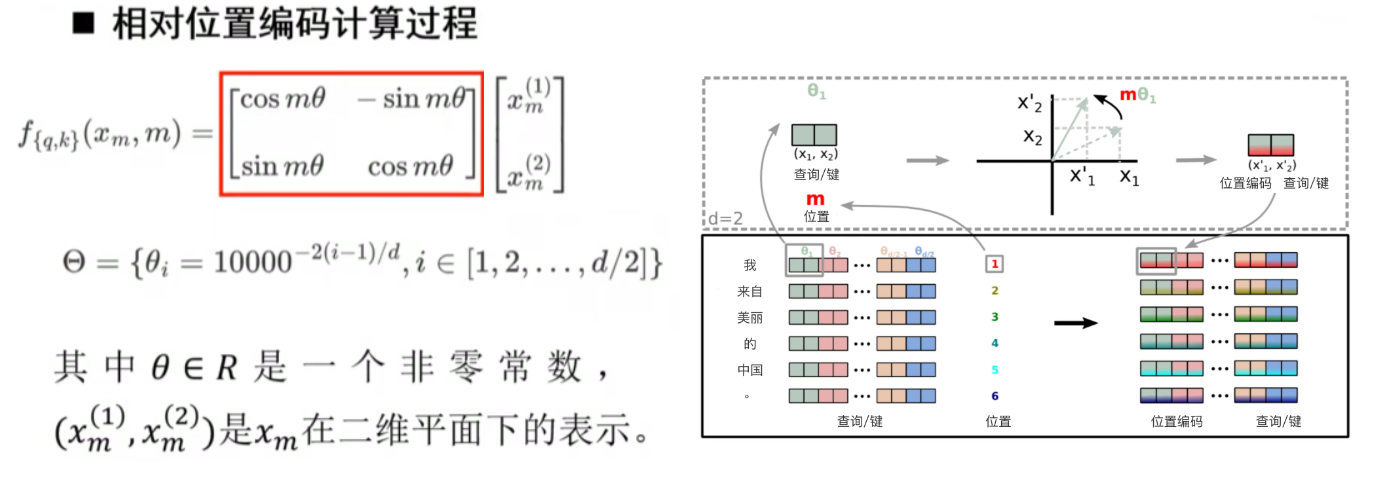

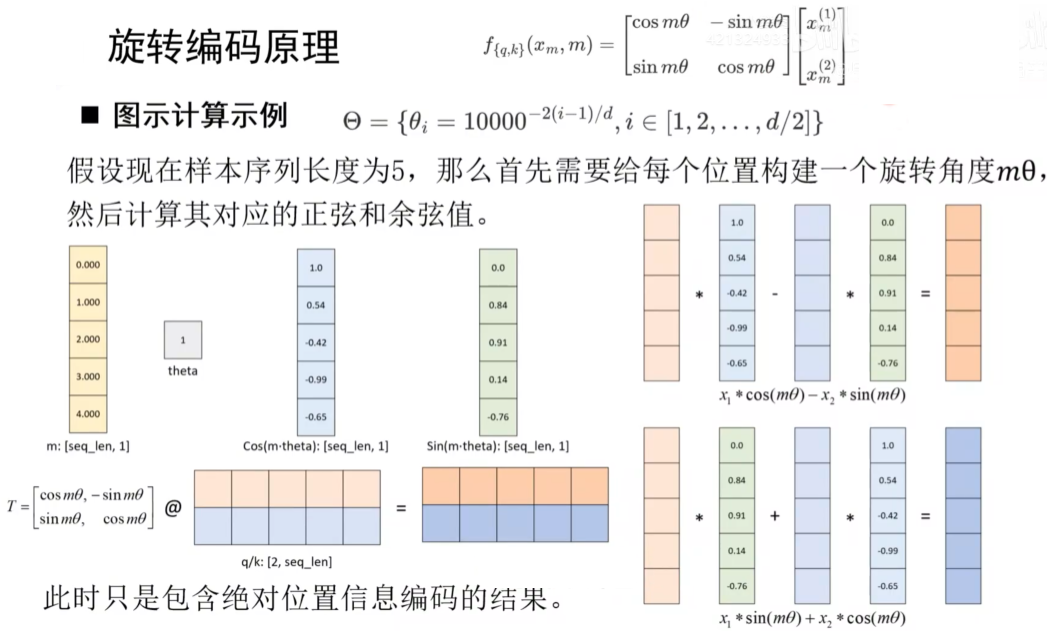

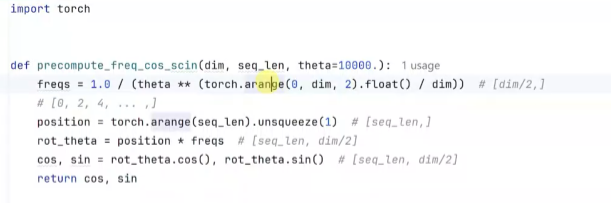

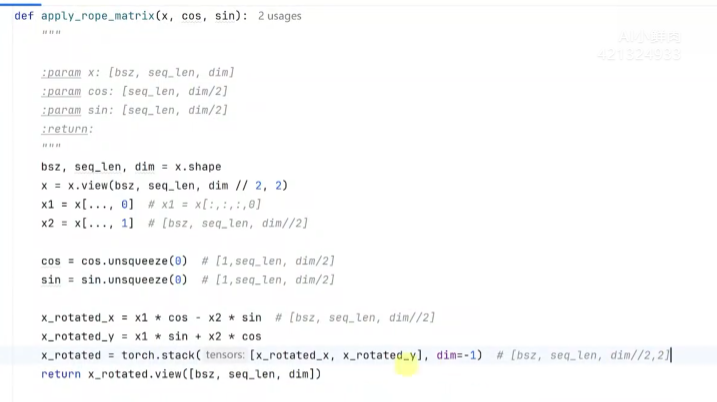

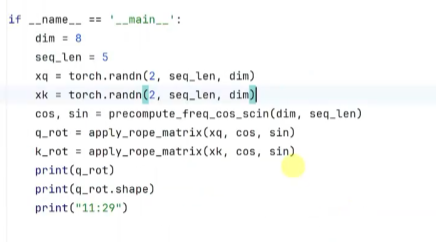

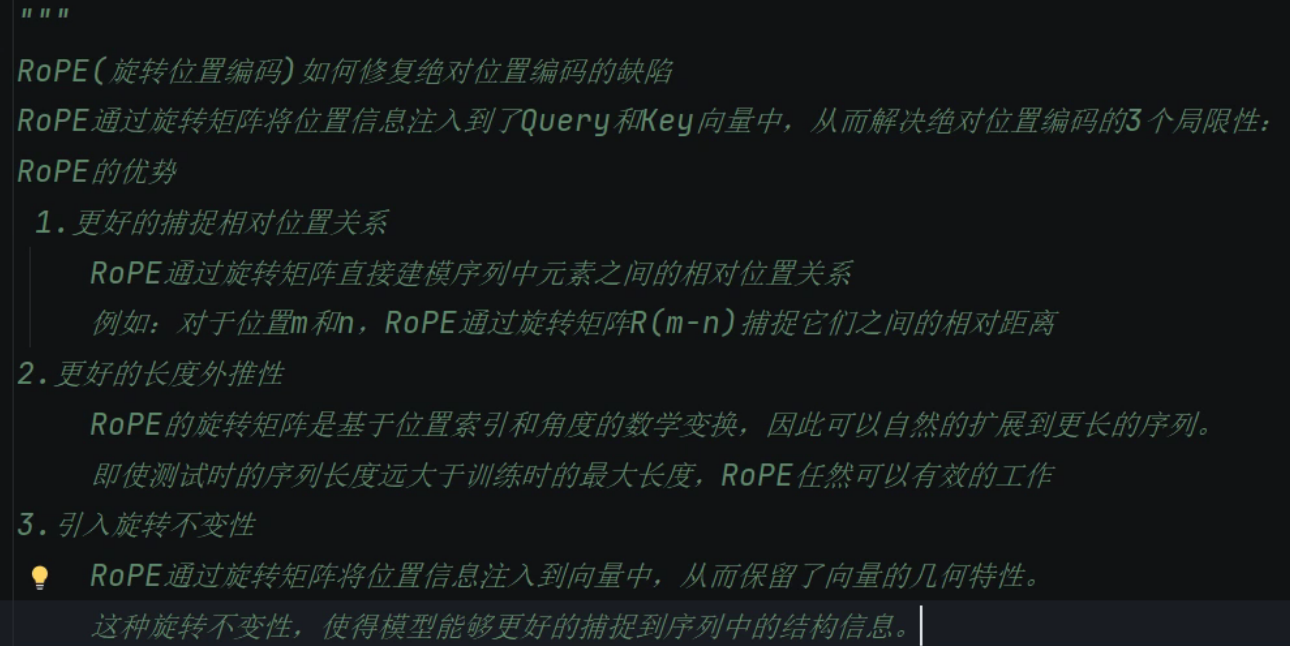

https://mp.weixin.qq.com/s/Ice6eLFDX1EaBOLP5kVyJQ

https://mp.weixin.qq.com/s/fkTKz7diNuW-_P-PYmMdxg

https://mp.weixin.qq.com/s/f4OjkpMLckZnLpwghZRBTw